# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Sebastian Hernandez Gutierrez
**Grupo:** 511 **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("../data/raw/nyc_taxi_examen.csv")

print("--- PRIMERAS 5 FILAS ---")
display(df.head())

print(f"\n--- DIMENSIONES DEL DATASET ---\nFilas: {df.shape[0]}, Columnas: {df.shape[1]}")

print("\n--- NOMBRES DE LAS COLUMNAS ---")
print(df.columns.tolist())

print("\n--- TIPOS DE DATOS ---")
print(df.dtypes)

print("\n--- RESUMEN ESTADÍSTICO ---")
display(df.describe())

print("\n--- VALORES EN PAYMENT_TYPE ---")
print(df['payment_type'].value_counts(dropna=False))

--- PRIMERAS 5 FILAS ---


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,1.0,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,1.0,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,1.0,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,1.0,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,1.0,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000



--- DIMENSIONES DEL DATASET ---
Filas: 2427612, Columnas: 20

--- NOMBRES DE LAS COLUMNAS ---
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

--- TIPOS DE DATOS ---
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type             float64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestio

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415487e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,1.174306e+00,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,4.594154e-01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,1.000000e+00,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.000000e+00,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,1.000000e+00,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03



--- VALORES EN PAYMENT_TYPE ---
payment_type
1.0    2051983
2.0     329533
4.0      23558
NaN      12125
3.0      10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [ ]:
df_limpio = df[df['payment_type'] == 2].copy()

print("--- ANTES DE LA LIMPIEZA (FILTRADO POR PAYMENT_TYPE == 2) ---")
print(f"Dimensiones iniciales (solo tipo 2): {df_limpio.shape}")
print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())
print(f"\nRegistros duplicados: {df_limpio.duplicated().sum()}")

df_limpio = df_limpio.drop_duplicates()
df_limpio = df_limpio.dropna()

condiciones = (
    (df_limpio['trip_distance'] > 0) &
    (df_limpio['passenger_count'] > 0) & (df_limpio['passenger_count'] < 100) &
    (df_limpio['fare_amount'] > 0) & (df_limpio['fare_amount'] < 10000) &
    (df_limpio['trip_duration'] > 0)
)
df_limpio = df_limpio[condiciones].copy()

print("\n--- DESPUÉS DE LA LIMPIEZA ---")
print(f"Dimensiones finales: {df_limpio.shape}")
print(f"Total de registros limpios restantes: {len(df_limpio)}")
print(f"Nulos restantes: {df_limpio.isnull().sum().sum()} | Duplicados restantes: {df_limpio.duplicated().sum()}")

--- ANTES DE LA LIMPIEZA (FILTRADO POR PAYMENT_TYPE == 2) ---
Dimensiones iniciales (solo tipo 2): (329533, 20)

Valores nulos por columna:
VendorID                    0
tpep_pickup_datetime     1625
tpep_dropoff_datetime    1667
passenger_count          1697
trip_distance            1635
RatecodeID               1622
PULocationID             1613
DOLocationID             1688
payment_type                0
fare_amount              1653
extra                    1674
mta_tax                  1560
tip_amount               1590
tolls_amount             1660
improvement_surcharge    1686
total_amount             1619
congestion_surcharge     1714
Airport_fee              1647
cbd_congestion_fee       1657
trip_duration            1550
dtype: int64

Registros duplicados: 1663

--- DESPUÉS DE LA LIMPIEZA ---
Dimensiones finales: (282085, 20)
Total de registros limpios restantes: 282085
Nulos restantes: 0 | Duplicados restantes: 0


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [ ]:
df_cash = df_limpio[df_limpio['payment_type'] == 2].copy()

X = df_cash[['trip_distance', 'trip_duration']].copy()

print(f"Cantidad de viajes pagados en efectivo (payment_type == 2): {len(df_cash)}")
print("\n--- ESTADÍSTICAS DESCRIPTIVAS DE X ---")
display(X.describe())

Cantidad de viajes pagados en efectivo (payment_type == 2): 282085

--- ESTADÍSTICAS DESCRIPTIVAS DE X ---


,trip_distance,trip_duration
count,282085.000000,282085.000000
mean,3.842165,17.507243
std,6.214391,40.684025
min,0.010000,0.033333
25%,0.920000,7.400000
50%,1.700000,12.416667
75%,4.370000,20.883333
max,1686.490000,8373.666667


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [ ]:
X_log = np.log1p(X)

scaler = StandardScaler()
X_escalado = scaler.fit_transform(X_log)

df_escalado = pd.DataFrame(X_escalado, columns=['trip_distance', 'trip_duration'])

print("--- RESUMEN ESTADÍSTICO DE VARIABLES TRANSFORMADAS Y ESTANDARIZADAS ---")
display(df_escalado.describe().round(4))

--- RESUMEN ESTADÍSTICO DE VARIABLES TRANSFORMADAS Y ESTANDARIZADAS ---


,trip_distance,trip_duration
count,282085.0000,282085.0000
mean,0.0000,-0.0000
std,1.0000,1.0000
min,-1.5924,-3.4587
25%,-0.7509,-0.6439
50%,-0.3042,-0.0149
75%,0.5966,0.6422
max,8.1299,8.6310


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

--- TABLA COMPARATIVA DE EVALUACIÓN ---


,k,Inercia,Silueta
0,2,227681.2292,0.5320
1,3,137511.9588,0.4478
2,4,100620.1949,0.4191
3,5,79205.3717,0.3894
4,6,66980.3104,0.3737


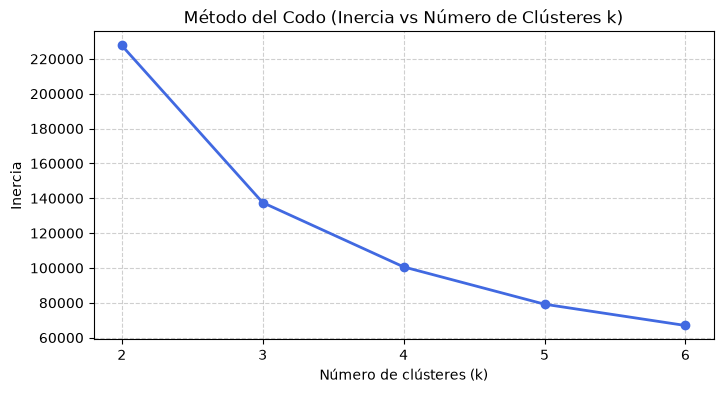

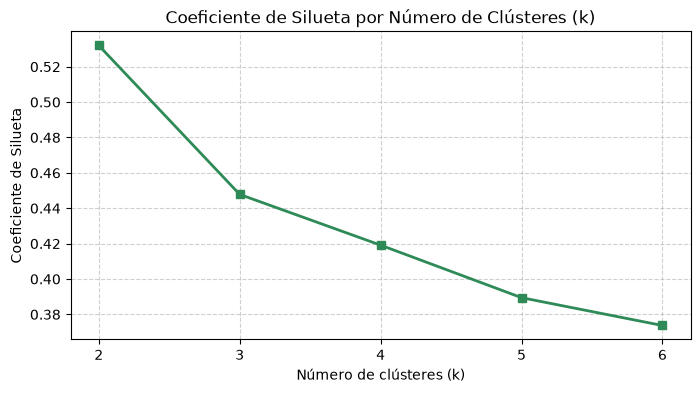

In [ ]:
valores_k = [2, 3, 4, 5, 6]
inercias = []
siluetas = []

for k in valores_k:
    
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = kmeans.fit_predict(X_escalado)
    
    inercias.append(kmeans.inertia_)
    
    
    score_sil = silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42)
    siluetas.append(score_sil)

tabla_evaluacion = pd.DataFrame({
    'k': valores_k,
    'Inercia': inercias,
    'Silueta': siluetas
})
print("--- TABLA COMPARATIVA DE EVALUACIÓN ---")
display(tabla_evaluacion.round(4))

plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercias, marker='o', linestyle='-', color='royalblue', linewidth=2)
plt.title('Método del Codo (Inercia vs Número de Clústeres k)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Inercia')
plt.xticks(valores_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(valores_k, siluetas, marker='s', linestyle='-', color='seagreen', linewidth=2)
plt.title('Coeficiente de Silueta por Número de Clústeres (k)')
plt.xlabel('Número de clústeres (k)')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(valores_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

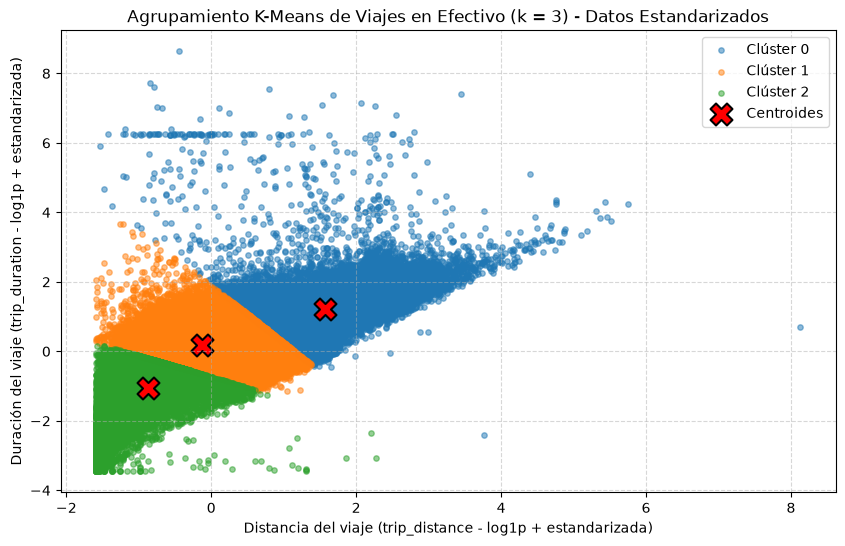

In [ ]:
k_elegido = 3

modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)

etiquetas_finales = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

plt.figure(figsize=(10, 6))

for i in range(k_elegido):
    puntos_cluster = X_escalado[etiquetas_finales == i]
    plt.scatter(
        puntos_cluster[:, 0], 
        puntos_cluster[:, 1], 
        s=15, 
        alpha=0.5, 
        label=f'Clúster {i}'
    )

plt.scatter(
    centroides[:, 0], 
    centroides[:, 1], 
    c='red', 
    marker='X', 
    s=250, 
    edgecolors='black', 
    linewidths=1.5,
    label='Centroides'
)

plt.title(f'Agrupamiento K-Means de Viajes en Efectivo (k = {k_elegido}) - Datos Estandarizados')
plt.xlabel('Distancia del viaje (trip_distance - log1p + estandarizada)')
plt.ylabel('Duración del viaje (trip_duration - log1p + estandarizada)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [11]:
df_resultado = df_cash.copy()

df_resultado['cluster'] = etiquetas_finales

tabla_estadisticos = df_resultado.groupby('cluster').agg(
    Cantidad_viajes=('trip_distance', 'count'),
    Media_distancia_mi=('trip_distance', 'mean'),
    Mediana_distancia_mi=('trip_distance', 'median'),
    Media_duracion_min=('trip_duration', 'mean'),
    Mediana_duracion_min=('trip_duration', 'median')
)

print("--- TABLA DE ESTADÍSTICOS POR CLÚSTER (UNIDADES ORIGINALES) ---")
display(tabla_estadisticos.round(2))

--- TABLA DE ESTADÍSTICOS POR CLÚSTER (UNIDADES ORIGINALES) ---


,Cantidad_viajes,Media_distancia_mi,Mediana_distancia_mi,Media_duracion_min,Mediana_duracion_min
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**
Elegí trabajar con k = 3 porque, al revisar la gráfica del método del codo, noté que la caída más pronunciada de la inercia se da al pasar de 2 a 3 clústeres (bajando de 227,681.23 a 137,511.96), y a partir de k = 4 (100,620.19) la curva empieza a suavizarse, por lo que agregar más grupos ya no reduce tanto la dispersión. Aunque k = 2 tiene la silueta más alta (0.5320), separar los viajes solo en dos grupos resulta muy general; en cambio, k = 3 mantiene un buen coeficiente de silueta de 0.4478 y permite distinguir claramente tres tipos de viajes bien diferenciados. 


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:** 
A partir de la tabla de estadísticos, identifiqué los siguientes tres perfiles de viajes pagados en efectivo:   Clúster 2 – "Viajes cortos o locales": Cuenta con 94,169 viajes. Tiene una distancia media de 0.80 millas (mediana de 0.76 millas) y una duración promedio de 5.72 minutos (mediana de 5.82 minutos). Representa traslados muy rápidos de unas cuantas cuadras dentro de la misma zona.   Clúster 1 – "Viajes urbanos de media distancia": Es el grupo más grande con 125,521 viajes. Registra una distancia promedio de 2.30 millas (mediana de 1.94 millas) y una duración media de 15.43 minutos (mediana de 14.00 minutos), lo que corresponde a recorridos cotidianos entre distintos vecindarios de la ciudad.   Clúster 0 – "Viajes largos o hacia periferia/aeropuerto": Agrupa 62,395 viajes. Presenta una distancia media de 11.55 millas (mediana de 9.81 millas) y una duración promedio de 39.48 minutos (mediana de 31.40 minutos), reflejando traslados extensos entre distritos lejanos o salidas hacia los aeropuertos.  


**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:**
El clúster que presenta la mayor duración promedio es el Clúster 0, alcanzando una media de 39.48 minutos (y una mediana de 31.40 minutos). Al revisar la tabla, se observa que sí coincide en tener también la mayor distancia promedio de los tres grupos, con 11.55 millas de media (y 9.81 millas de mediana). Esto es totalmente coherente, ya que al tratarse de los recorridos más largos por la ciudad, requieren proporcionalmente mucho más tiempo de traslado que el resto de los grupos.


**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:**
El grupo más numeroso es el Clúster 1, que concentra 125,521 viajes (seguido por el Clúster 2 con 94,169 viajes y el Clúster 0 con 62,395). En este grupo predominan los viajes de distancia intermedia/moderada, con un promedio de 2.30 millas (mediana de 1.94 millas) y tiempos de recorrido que rondan los 15.43 minutos en promedio (mediana de 14.00 minutos). Esto muestra que el uso más frecuente del taxi pagado en efectivo en Nueva York es para traslados urbanos de distancia media que toman alrededor de un cuarto de hora.

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**